PART-A

In [1]:
print("RITHANYA.G 24BAD132")

!pip install transformers datasets torch scikit-learn accelerate -q

RITHANYA.G 24BAD132


In [2]:
print("RITHANYA.G 24BAD132")

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import AutoTokenizer
from torch.utils.data import DataLoader

print("All libraries imported successfully!")
print("GPU Available:", torch.cuda.is_available())

RITHANYA.G 24BAD132
All libraries imported successfully!
GPU Available: True


In [3]:
print("RITHANYA.G 24BAD132")

dataset = load_dataset("stanfordnlp/imdb")

print(dataset)

RITHANYA.G 24BAD132


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [4]:
print("RITHANYA.G 24BAD132")

print("Training samples:", len(dataset["train"]))
print("Testing samples:", len(dataset["test"]))

print("\nSample Review:")
print(dataset["train"][0]["text"])

print("\nSample Label:")
print(dataset["train"][0]["label"])

RITHANYA.G 24BAD132
Training samples: 25000
Testing samples: 25000

Sample Review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was cons

RITHANYA.G 24BAD132
0 = Negative
1 = Positive
0    12500
1    12500
Name: count, dtype: int64


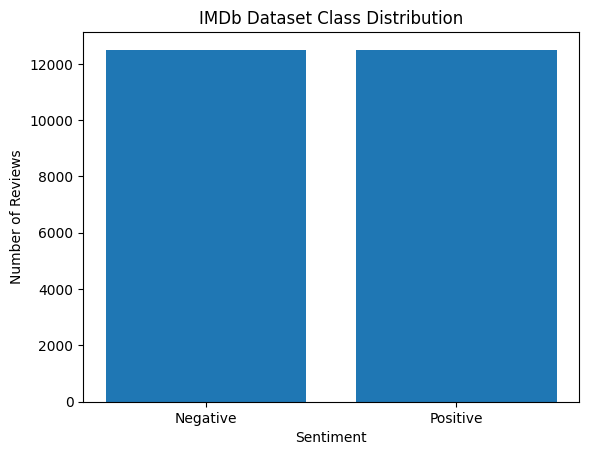

In [5]:
print("RITHANYA.G 24BAD132")

labels = dataset["train"]["label"]

label_counts = pd.Series(labels).value_counts().sort_index()

print("0 = Negative")
print("1 = Positive")
print(label_counts)

plt.bar(["Negative", "Positive"], label_counts.values)
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.title("IMDb Dataset Class Distribution")
plt.show()


In [6]:
print("RITHANYA.G 24BAD132")

tokenizer = AutoTokenizer.from_pretrained("google-bert/bert-base-uncased")

print("BERT Tokenizer Loaded Successfully!")

RITHANYA.G 24BAD132


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT Tokenizer Loaded Successfully!


In [7]:
print("RITHANYA.G 24BAD132")

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

tokenized_dataset = dataset.map(tokenize_function, batched=True)

print("Dataset Tokenized Successfully!")
print(tokenized_dataset)

RITHANYA.G 24BAD132


Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset Tokenized Successfully!
DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 50000
    })
})


In [8]:
print("RITHANYA.G 24BAD132")

train_dataset = tokenized_dataset["train"]
test_dataset = tokenized_dataset["test"]

train_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "label"]
)

test_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "label"]
)

print("Training Dataset Prepared:", len(train_dataset))
print("Testing Dataset Prepared:", len(test_dataset))

RITHANYA.G 24BAD132
Training Dataset Prepared: 25000
Testing Dataset Prepared: 25000


In [9]:
print("RITHANYA.G 24BAD132")

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

batch = next(iter(train_loader))

print("Input IDs Shape:", batch["input_ids"].shape)
print("Attention Mask Shape:", batch["attention_mask"].shape)
print("Labels Shape:", batch["label"].shape)

print("Dataset Preparation Completed Successfully!")

RITHANYA.G 24BAD132
Training batches: 1563
Testing batches: 1563
Input IDs Shape: torch.Size([16, 128])
Attention Mask Shape: torch.Size([16, 128])
Labels Shape: torch.Size([16])
Dataset Preparation Completed Successfully!


PART-B


In [10]:
print("RITHANYA.G 24BAD132")

from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np
import torch

print("Libraries imported successfully!")

RITHANYA.G 24BAD132
Libraries imported successfully!


In [11]:
print("RITHANYA.G 24BAD132")

model = AutoModelForSequenceClassification.from_pretrained(
    "google-bert/bert-base-uncased",
    num_labels=2
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print("BERT Model Loaded Successfully!")
print("Device:", device)

RITHANYA.G 24BAD132


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT Model Loaded Successfully!
Device: cuda


In [12]:
print("RITHANYA.G 24BAD132")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Evaluation Metrics Defined Successfully!")

RITHANYA.G 24BAD132
Evaluation Metrics Defined Successfully!


In [13]:
print("RITHANYA.G 24BAD132")

training_args = TrainingArguments(
    output_dir="./bert_imdb_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=100,
    report_to="none"
)

print("Training Parameters Configured Successfully!")

RITHANYA.G 24BAD132
Training Parameters Configured Successfully!


In [14]:
print("RITHANYA.G 24BAD132")

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

print("Trainer Initialized Successfully!")

RITHANYA.G 24BAD132
Trainer Initialized Successfully!


In [15]:
print("RITHANYA.G 24BAD132")

trainer.train()

print("BERT Fine-Tuning Completed Successfully!")

RITHANYA.G 24BAD132


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.288840,0.287054,0.885640,0.899346,0.868480,0.883643
2,0.182258,0.326854,0.893080,0.882761,0.906560,0.894502


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT Fine-Tuning Completed Successfully!


In [16]:
print("RITHANYA.G 24BAD132")

results = trainer.evaluate()

print("\nBERT MODEL EVALUATION RESULTS")

for key, value in results.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

RITHANYA.G 24BAD132


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.182258,0.326854,2,0.893080,0.882761,0.906560,0.894502



BERT MODEL EVALUATION RESULTS
eval_loss: 0.3269
eval_accuracy: 0.8931
eval_precision: 0.8828
eval_recall: 0.9066
eval_f1: 0.8945


In [17]:
print("RITHANYA.G 24BAD132")

def predict_sentiment(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=128
    ).to(device)

    model.eval()

    with torch.no_grad():
        outputs = model(**inputs)

    prediction = torch.argmax(outputs.logits, dim=1).item()

    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", text)
    print("Predicted Sentiment:", sentiment)
    print("-" * 50)


predict_sentiment("This movie was amazing and I enjoyed every moment.")
predict_sentiment("The movie was boring and a complete waste of time.")
predict_sentiment("The story was wonderful and the acting was excellent.")
predict_sentiment("I hated this movie. It was terrible and disappointing.")

RITHANYA.G 24BAD132
Review: This movie was amazing and I enjoyed every moment.
Predicted Sentiment: Positive
--------------------------------------------------
Review: The movie was boring and a complete waste of time.
Predicted Sentiment: Negative
--------------------------------------------------
Review: The story was wonderful and the acting was excellent.
Predicted Sentiment: Positive
--------------------------------------------------
Review: I hated this movie. It was terrible and disappointing.
Predicted Sentiment: Negative
--------------------------------------------------


In [18]:
print("RITHANYA.G 24BAD132")

model.save_pretrained("./bert_imdb_model")
tokenizer.save_pretrained("./bert_imdb_model")

print("Model and Tokenizer Saved Successfully!")

RITHANYA.G 24BAD132


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and Tokenizer Saved Successfully!


RITHANYA.G 24BAD132


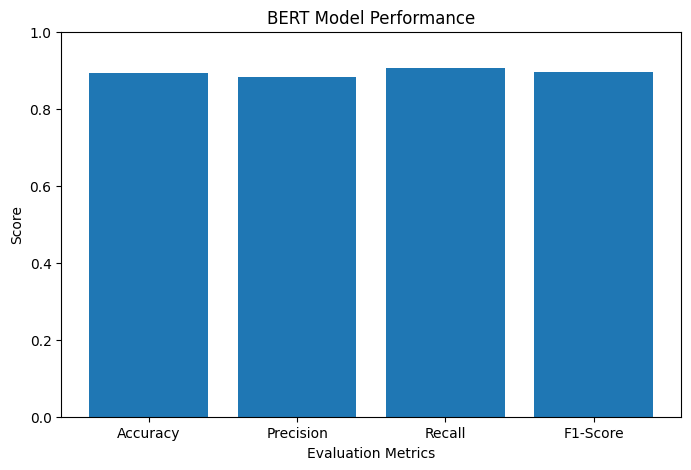

      Metric     Score
0   Accuracy  0.893080
1  Precision  0.882761
2     Recall  0.906560
3   F1-Score  0.894502


In [19]:
print("RITHANYA.G 24BAD132")

metrics = {
    "Accuracy": results["eval_accuracy"],
    "Precision": results["eval_precision"],
    "Recall": results["eval_recall"],
    "F1-Score": results["eval_f1"]
}

plt.figure(figsize=(8, 5))
plt.bar(metrics.keys(), metrics.values())
plt.ylim(0, 1)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("BERT Model Performance")
plt.show()

print(pd.DataFrame(metrics.items(), columns=["Metric", "Score"]))

PART-C

In [20]:
print("RITHANYA.G 24BAD132")

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch
import pandas as pd

print("Libraries imported successfully!")

RITHANYA.G 24BAD132
Libraries imported successfully!


In [21]:
print("RITHANYA.G 24BAD132")

t5_model_name = "google-t5/t5-small"

t5_tokenizer = AutoTokenizer.from_pretrained(t5_model_name)

t5_model = AutoModelForSeq2SeqLM.from_pretrained(t5_model_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

t5_model.to(device)

print("T5-small Model Loaded Successfully!")
print("Device:", device)

RITHANYA.G 24BAD132


config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5-small Model Loaded Successfully!
Device: cuda


In [22]:
print("RITHANYA.G 24BAD132")

input_texts = [
    "summarize: Artificial Intelligence is a branch of computer science that enables machines to perform tasks that normally require human intelligence.",
    "summarize: Machine learning is a technology that allows computers to learn from data and improve their performance without being explicitly programmed.",
    "summarize: Natural Language Processing helps computers understand, interpret and generate human language."
]

print("Sample Inputs Prepared Successfully!")

for text in input_texts:
    print("\n", text)

RITHANYA.G 24BAD132
Sample Inputs Prepared Successfully!

 summarize: Artificial Intelligence is a branch of computer science that enables machines to perform tasks that normally require human intelligence.

 summarize: Machine learning is a technology that allows computers to learn from data and improve their performance without being explicitly programmed.

 summarize: Natural Language Processing helps computers understand, interpret and generate human language.


In [23]:
print("RITHANYA.G 24BAD132")

inputs = t5_tokenizer(
    input_texts,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=128
).to(device)

print("Input Text Preprocessed Successfully!")
print("Input IDs Shape:", inputs["input_ids"].shape)
print("Attention Mask Shape:", inputs["attention_mask"].shape)

RITHANYA.G 24BAD132
Input Text Preprocessed Successfully!
Input IDs Shape: torch.Size([3, 27])
Attention Mask Shape: torch.Size([3, 27])


In [24]:
print("RITHANYA.G 24BAD132")

t5_model.eval()

with torch.no_grad():
    outputs = t5_model.generate(
        inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        max_length=50,
        num_beams=4,
        early_stopping=True
    )

generated_texts = t5_tokenizer.batch_decode(
    outputs,
    skip_special_tokens=True
)

print("Text Generation Completed Successfully!")

for i in range(len(input_texts)):
    print("\nInput:", input_texts[i])
    print("Generated Output:", generated_texts[i])

RITHANYA.G 24BAD132
Text Generation Completed Successfully!

Input: summarize: Artificial Intelligence is a branch of computer science that enables machines to perform tasks that normally require human intelligence.
Generated Output: artificial intelligence is a branch of computer science that enables machines to perform tasks that normally require human intelligence.

Input: summarize: Machine learning is a technology that allows computers to learn from data and improve their performance without being explicitly programmed.
Generated Output: machine learning is a technology that allows computers to learn from data without being explicitly programmed.

Input: summarize: Natural Language Processing helps computers understand, interpret and generate human language.
Generated Output: natural language processing helps computers understand, interpret and generate human language.


In [25]:
print("RITHANYA.G 24BAD132")

sample_text = "summarize: Deep learning uses neural networks with multiple layers to learn complex patterns from large amounts of data."

sample_input = t5_tokenizer(
    sample_text,
    return_tensors="pt",
    truncation=True,
    max_length=128
).to(device)

with torch.no_grad():
    greedy_output = t5_model.generate(
        sample_input["input_ids"],
        max_length=50
    )

    beam_output = t5_model.generate(
        sample_input["input_ids"],
        max_length=50,
        num_beams=4,
        early_stopping=True
    )

print("Original Input:", sample_text)

print("\nGreedy Search Output:")
print(t5_tokenizer.decode(greedy_output[0], skip_special_tokens=True))

print("\nBeam Search Output:")
print(t5_tokenizer.decode(beam_output[0], skip_special_tokens=True))

RITHANYA.G 24BAD132
Original Input: summarize: Deep learning uses neural networks with multiple layers to learn complex patterns from large amounts of data.

Greedy Search Output:
deep learning uses neural networks with multiple layers to learn patterns.

Beam Search Output:
deep learning uses neural networks with multiple layers to learn patterns from large amounts of data.


In [26]:
print("RITHANYA.G 24BAD132")

test_inputs = [
    "summarize: Cloud computing provides computing services such as storage, servers and databases over the internet.",
    "summarize: Data science combines statistics, programming and machine learning to extract useful information from data.",
    "summarize: Robotics is a field of technology that focuses on designing and building machines that perform tasks automatically."
]

test_tokens = t5_tokenizer(
    test_inputs,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=128
).to(device)

with torch.no_grad():
    test_outputs = t5_model.generate(
        test_tokens["input_ids"],
        attention_mask=test_tokens["attention_mask"],
        max_length=50,
        num_beams=4
    )

test_generated = t5_tokenizer.batch_decode(
    test_outputs,
    skip_special_tokens=True
)

for i in range(len(test_inputs)):
    print("\nInput:", test_inputs[i])
    print("Generated:", test_generated[i])
    print("-" * 50)

RITHANYA.G 24BAD132

Input: summarize: Cloud computing provides computing services such as storage, servers and databases over the internet.
Generated: cloud computing provides computing services such as storage, servers and databases over the internet.
--------------------------------------------------

Input: summarize: Data science combines statistics, programming and machine learning to extract useful information from data.
Generated: data science combines statistics, programming and machine learning to extract useful information from data.
--------------------------------------------------

Input: summarize: Robotics is a field of technology that focuses on designing and building machines that perform tasks automatically.
Generated: robotics is a field of technology that focuses on designing and building machines that perform tasks automatically.
--------------------------------------------------


In [27]:
print("RITHANYA.G 24BAD132")

output_df = pd.DataFrame({
    "Input Text": input_texts,
    "Generated Text": generated_texts
})

output_df.to_csv("t5_generated_outputs.csv", index=False)

print("Generated Outputs Saved Successfully!")

print(output_df)

RITHANYA.G 24BAD132
Generated Outputs Saved Successfully!
                                          Input Text  \
0  summarize: Artificial Intelligence is a branch...   
1  summarize: Machine learning is a technology th...   
2  summarize: Natural Language Processing helps c...   

                                      Generated Text  
0  artificial intelligence is a branch of compute...  
1  machine learning is a technology that allows c...  
2  natural language processing helps computers un...  


PART-D

In [28]:
print("RITHANYA.G 24BAD132")

test_reviews = [
    "This movie was fantastic, amazing and highly entertaining.",
    "The movie was boring, disappointing and a waste of time.",
    "I loved the story and the actors performed brilliantly.",
    "The film was terrible and I would never recommend it."
]

for review in test_reviews:
    predict_sentiment(review)

RITHANYA.G 24BAD132
Review: This movie was fantastic, amazing and highly entertaining.
Predicted Sentiment: Positive
--------------------------------------------------
Review: The movie was boring, disappointing and a waste of time.
Predicted Sentiment: Negative
--------------------------------------------------
Review: I loved the story and the actors performed brilliantly.
Predicted Sentiment: Positive
--------------------------------------------------
Review: The film was terrible and I would never recommend it.
Predicted Sentiment: Negative
--------------------------------------------------


In [29]:
print("RITHANYA.G 24BAD132")

results = trainer.evaluate()

print("BERT CLASSIFICATION PERFORMANCE")
print("Accuracy:", round(results["eval_accuracy"], 4))
print("Precision:", round(results["eval_precision"], 4))
print("Recall:", round(results["eval_recall"], 4))
print("F1-Score:", round(results["eval_f1"], 4))

RITHANYA.G 24BAD132


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.182258,0.326854,2,0.893080,0.882761,0.906560,0.894502


BERT CLASSIFICATION PERFORMANCE
Accuracy: 0.8931
Precision: 0.8828
Recall: 0.9066
F1-Score: 0.8945


In [30]:
print("RITHANYA.G 24BAD132")

new_inputs = [
    "summarize: Artificial Intelligence helps machines perform tasks that require human intelligence.",
    "summarize: Cloud computing provides online access to computing resources such as storage and servers.",
    "summarize: Machine learning enables computers to learn patterns from data and make predictions."
]

new_tokens = t5_tokenizer(
    new_inputs,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=128
).to(device)

with torch.no_grad():
    new_outputs = t5_model.generate(
        new_tokens["input_ids"],
        attention_mask=new_tokens["attention_mask"],
        max_length=50,
        num_beams=4
    )

new_generated = t5_tokenizer.batch_decode(
    new_outputs,
    skip_special_tokens=True
)

for i in range(len(new_inputs)):
    print("\nInput:", new_inputs[i])
    print("Generated Output:", new_generated[i])
    print("-" * 50)

RITHANYA.G 24BAD132

Input: summarize: Artificial Intelligence helps machines perform tasks that require human intelligence.
Generated Output: artificial intelligence helps machines perform tasks that require human intelligence.
--------------------------------------------------

Input: summarize: Cloud computing provides online access to computing resources such as storage and servers.
Generated Output: cloud computing provides online access to computing resources such as storage and servers.
--------------------------------------------------

Input: summarize: Machine learning enables computers to learn patterns from data and make predictions.
Generated Output: machine learning enables computers to learn patterns from data.
--------------------------------------------------


In [31]:
print("RITHANYA.G 24BAD132")

sample = "summarize: Natural Language Processing allows computers to understand and generate human language."

sample_tokens = t5_tokenizer(
    sample,
    return_tensors="pt",
    truncation=True,
    max_length=128
).to(device)

with torch.no_grad():
    output1 = t5_model.generate(
        sample_tokens["input_ids"],
        max_length=50,
        num_beams=1
    )

    output2 = t5_model.generate(
        sample_tokens["input_ids"],
        max_length=50,
        num_beams=4
    )

print("Original Input:", sample)

print("\nGreedy Search:")
print(t5_tokenizer.decode(output1[0], skip_special_tokens=True))

print("\nBeam Search:")
print(t5_tokenizer.decode(output2[0], skip_special_tokens=True))

RITHANYA.G 24BAD132
Original Input: summarize: Natural Language Processing allows computers to understand and generate human language.

Greedy Search:
natural language processing allows computers to understand and generate human language.

Beam Search:
natural language processing allows computers to understand and generate human language.


In [32]:
print("RITHANYA.G 24BAD132")

comparison = pd.DataFrame({
    "Model": ["BERT", "T5-small"],
    "Task": ["Text Classification", "Text Generation"],
    "Application": ["Sentiment Analysis", "Text Summarization"]
})

print(comparison)

comparison.to_csv("model_comparison.csv", index=False)

print("\nModel Comparison Saved Successfully!")

RITHANYA.G 24BAD132
      Model                 Task         Application
0      BERT  Text Classification  Sentiment Analysis
1  T5-small      Text Generation  Text Summarization

Model Comparison Saved Successfully!


RITHANYA.G 24BAD132


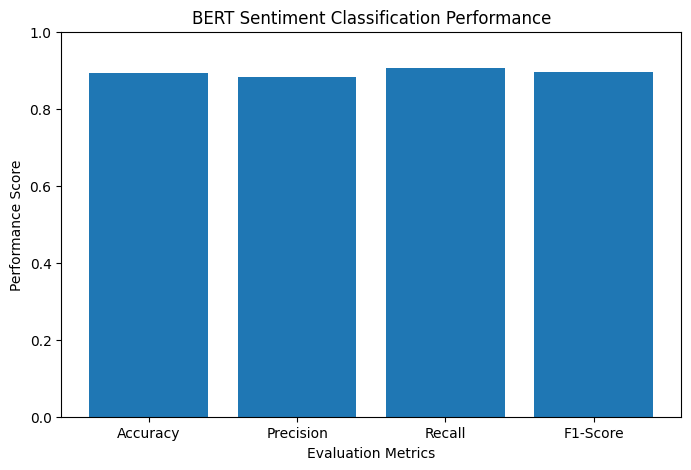

Performance Analysis Completed!


In [33]:
print("RITHANYA.G 24BAD132")

metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]

metric_values = [
    results["eval_accuracy"],
    results["eval_precision"],
    results["eval_recall"],
    results["eval_f1"]
]

plt.figure(figsize=(8, 5))
plt.bar(metric_names, metric_values)
plt.ylim(0, 1)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Performance Score")
plt.title("BERT Sentiment Classification Performance")
plt.show()

print("Performance Analysis Completed!")